# Load Dataset and libraries, Preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import re

In [2]:
data = pd.read_csv('data/Hospital_Readmissions_and_Deaths.csv')

# Information about the data
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64764 entries, 0 to 64763
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   index                 64764 non-null  int64 
 1   Provider ID           64764 non-null  int64 
 2   Hospital Name         64764 non-null  object
 3   Address               64764 non-null  object
 4   City                  64764 non-null  object
 5   State                 64764 non-null  object
 6   ZIP Code              64764 non-null  int64 
 7   County Name           64582 non-null  object
 8   Phone Number          64764 non-null  int64 
 9   Measure Name          64764 non-null  object
 10  Measure ID            64764 non-null  object
 11  Compared to National  64764 non-null  object
 12  Denominator           64764 non-null  object
 13  Score                 64764 non-null  object
 14  Lower Estimate        64764 non-null  object
 15  Higher Estimate       64764 non-null

Denominator, Score, Lower Estimate, Higher Estimate are numerical values but being shown as strings due to "Not Available" in some rows

# Data Cleaning

In [3]:
data.columns = data.columns.str.lower().str.replace(" ", "_")

display(data.describe())
print(data.shape)

,index,provider_id,zip_code,phone_number
count,64764.000000,64764.000000,64764.000000,6.476400e+04
mean,32381.500000,266295.217250,53713.003243,5.842244e+09
std,18695.900754,155729.601498,26916.617580,2.331479e+09
min,0.000000,10001.000000,603.000000,9.369338e+08
25%,16190.750000,140172.000000,32803.000000,3.869175e+09
50%,32381.500000,251334.500000,55015.000000,6.037655e+09
75%,48572.250000,390137.000000,75701.000000,7.877233e+09
max,64763.000000,670108.000000,99929.000000,9.898943e+09


(64764, 20)


In [4]:
# Identifying Missing values in the data
data.isnull().sum()

index                       0
provider_id                 0
hospital_name               0
address                     0
city                        0
state                       0
zip_code                    0
county_name               182
phone_number                0
measure_name                0
measure_id                  0
compared_to_national        0
denominator                 0
score                       0
lower_estimate              0
higher_estimate             0
footnote                41785
measure_start_date          0
measure_end_date            0
location                    0
dtype: int64

There are 182 missing values in county name and 41785 missing values in footnote i prefer not to drop these missing values because dropping them will lead to losing some important data and also there are no duplicate rows and no type conversion is needed.

In [5]:
#Replacing "Not Available" to NaN for numeric columns to fit in their datatypes accordingly (object --> float)
data = data.replace('Not Available', np.nan)

#Replacing NaN values with "Not Available" for categorical column to measure the availability of reports later
data["compared_to_national"] = data["compared_to_national"].replace(np.nan, "Not Available")
data

,index,provider_id,hospital_name,address,city,state,zip_code,county_name,phone_number,measure_name,measure_id,compared_to_national,denominator,score,lower_estimate,higher_estimate,footnote,measure_start_date,measure_end_date,location
0,0,230100,TAWAS ST JOSEPH HOSPITAL,200 HEMLOCK,TAWAS CITY,MI,48764,IOSCO,9893629301,Rate of readmission after discharge from hospi...,READM_30_HOSP_WIDE,No Different than the National Rate,438,13.9,12.6,15.6,NaN,07/01/2014,06/30/2015,"200 HEMLOCK\nTAWAS CITY, MI 48764\n(44.274911,..."
1,1,230121,MEMORIAL HEALTHCARE,826 WEST KING STREET,OWOSSO,MI,48867,SHIAWASSEE,9897235211,Rate of readmission after hip/knee replacement,READM_30_HIP_KNEE,No Different than the National Rate,150,4.0,2.8,5.7,NaN,07/01/2012,06/30/2015,"826 WEST KING STREET\nOWOSSO, MI 48867\n(43.00..."
2,2,230118,HURON MEDICAL CENTER,1100 SOUTH VAN DYKE ROAD,BAD AXE,MI,48413,HURON,9892699521,Pneumonia (PN) 30-Day Readmission Rate,READM_30_PN,No Different than the National Rate,205,16.7,13.8,19.9,NaN,07/01/2012,06/30/2015,"1100 SOUTH VAN DYKE ROAD\nBAD AXE, MI 48413\n(..."
3,3,230121,MEMORIAL HEALTHCARE,826 WEST KING STREET,OWOSSO,MI,48867,SHIAWASSEE,9897235211,Rate of readmission for stroke patients,READM_30_STK,No Different than the National Rate,67,11.5,8.7,14.9,NaN,07/01/2012,06/30/2015,"826 WEST KING STREET\nOWOSSO, MI 48867\n(43.00..."
4,4,230133,OTSEGO MEMORIAL HOSPITAL,825 N CENTER AVE,GAYLORD,MI,49735,OTSEGO,9897312100,Heart failure (HF) 30-Day Mortality Rate,MORT_30_HF,No Different than the National Rate,102,13.4,9.9,17.7,NaN,07/01/2012,06/30/2015,"825 N CENTER AVE\nGAYLORD, MI 49735\n(45.03537..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64759,64759,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for stroke patients,READM_30_STK,Not Available,NaN,NaN,NaN,NaN,5 - Results are not available for this reporti...,07/01/2012,06/30/2015,"810 W HIGHWAY 71\nMARBLE FALLS, TX 78654\n(30...."
64760,64760,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for CABG,READM_30_CABG,Not Available,NaN,NaN,NaN,NaN,5 - Results are not available for this reporti...,07/01/2012,06/30/2015,"810 W HIGHWAY 71\nMARBLE FALLS, TX 78654\n(30...."
64761,64761,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Death rate for stroke patients,MORT_30_STK,Not Available,NaN,NaN,NaN,NaN,5 - Results are not available for this reporti...,07/01/2012,06/30/2015,"810 W HIGHWAY 71\nMARBLE FALLS, TX 78654\n(30...."
64762,64762,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for chronic obstructive pu...,READM_30_COPD,Not Available,NaN,NaN,NaN,NaN,5 - Results are not available for this reporti...,07/01/2012,06/30/2015,"810 W HIGHWAY 71\nMARBLE FALLS, TX 78654\n(30...."


In [6]:
# Fixing appropraite datatypes for the numerical and datetime columns 
data[["denominator", "score", "lower_estimate", "higher_estimate"]] = data[["denominator", "score", "lower_estimate", "higher_estimate"]].astype(float)
data[["measure_start_date", "measure_end_date"]] = data[["measure_start_date", "measure_end_date"]].apply(pd.to_datetime)

In [7]:
columns = ["county_name", "compared_to_national", "denominator", "score", "lower_estimate", "higher_estimate"]

for col in columns:
    missing_pct = round((data[col].isnull().sum() / len(data[col])) * 100, 2)
    print(f'Percentage of rows having missing values in {col} column is: {missing_pct}%')

Percentage of rows having missing values in county_name column is: 0.28%
Percentage of rows having missing values in compared_to_national column is: 0.0%
Percentage of rows having missing values in denominator column is: 35.48%
Percentage of rows having missing values in score column is: 35.48%
Percentage of rows having missing values in lower_estimate column is: 35.48%
Percentage of rows having missing values in higher_estimate column is: 35.48%


In [8]:
# Extract latitude and longitude using regex
data[["latitude", "longitude"]] = data["location"].str.extract(r"\(([-\d.]+),\s*([-\d.]+)\)")

data["latitude"] = data["latitude"].astype(float)
data["longitude"] = data["longitude"].astype(float)

In [9]:
# This is a cross-sectional data
# Extract year and month from start and end dates
data["start_year"] = data["measure_start_date"].dt.year
data["start_month"] = data["measure_start_date"].dt.month
data["end_year"] = data["measure_end_date"].dt.year
data["end_month"] = data["measure_end_date"].dt.month

# Calculate duration in days
data["duration_days"] = (data["measure_end_date"] - data["measure_start_date"]).dt.days


In [10]:
# Creating Short measure names for ease ("Measure short") and creating a new column ("Measure type") to categorize between Readmission and Mortality
conditions = [(data["measure_id"] == "READM_30_HOSP_WIDE"),
              (data["measure_id"] == "READM_30_HIP_KNEE"),
              (data["measure_id"] == "READM_30_PN"),
              (data["measure_id"] == "READM_30_STK"),
              (data["measure_id"] == "MORT_30_HF"),
              (data["measure_id"] == "MORT_30_PN"),
              (data["measure_id"] == "MORT_30_COPD"),
              (data["measure_id"] == "READM_30_HF"),
              (data["measure_id"] == "READM_30_AMI"),
              (data["measure_id"] == "MORT_30_AMI"),
              (data["measure_id"] == "MORT_30_CABG"),
              (data["measure_id"] == "MORT_30_STK"),
              (data["measure_id"] == "READM_30_CABG"),
              (data["measure_id"] == "READM_30_COPD")]

choices = ["Readmission Hospital Wide",
           "Readmission Hip Knee Replacement",
           "Readmission Pneumonia",
           "Readmission Stroke Patients",
           "Mortality Heart Failure",
           "Mortality Pneumonia",
           "Mortality COPD",
           "Readmission Heart Failure",
           "Readmission AMI",
           "Mortality AMI",
           "Mortality CABG",
           "Mortality Stroke Patients",
           "Readmission CABG",
           "Readmission COPD"]

data["measure_short"] = np.select(conditions, choices, default='Other')
pattern = r'^R.*'
is_match = np.vectorize(lambda x: bool(re.match(pattern, x)))(data["measure_short"])
data["measure_type"] = np.where(is_match, "Readmission","Mortality")

data

,index,provider_id,hospital_name,address,city,state,zip_code,county_name,phone_number,measure_name,...,location,latitude,longitude,start_year,start_month,end_year,end_month,duration_days,measure_short,measure_type
0,0,230100,TAWAS ST JOSEPH HOSPITAL,200 HEMLOCK,TAWAS CITY,MI,48764,IOSCO,9893629301,Rate of readmission after discharge from hospi...,...,"200 HEMLOCK\nTAWAS CITY, MI 48764\n(44.274911,...",44.274911,-83.511002,2014,7,2015,6,364,Readmission Hospital Wide,Readmission
1,1,230121,MEMORIAL HEALTHCARE,826 WEST KING STREET,OWOSSO,MI,48867,SHIAWASSEE,9897235211,Rate of readmission after hip/knee replacement,...,"826 WEST KING STREET\nOWOSSO, MI 48867\n(43.00...",43.005075,-84.182076,2012,7,2015,6,1094,Readmission Hip Knee Replacement,Readmission
2,2,230118,HURON MEDICAL CENTER,1100 SOUTH VAN DYKE ROAD,BAD AXE,MI,48413,HURON,9892699521,Pneumonia (PN) 30-Day Readmission Rate,...,"1100 SOUTH VAN DYKE ROAD\nBAD AXE, MI 48413\n(...",43.802281,-83.031509,2012,7,2015,6,1094,Readmission Pneumonia,Readmission
3,3,230121,MEMORIAL HEALTHCARE,826 WEST KING STREET,OWOSSO,MI,48867,SHIAWASSEE,9897235211,Rate of readmission for stroke patients,...,"826 WEST KING STREET\nOWOSSO, MI 48867\n(43.00...",43.005075,-84.182076,2012,7,2015,6,1094,Readmission Stroke Patients,Readmission
4,4,230133,OTSEGO MEMORIAL HOSPITAL,825 N CENTER AVE,GAYLORD,MI,49735,OTSEGO,9897312100,Heart failure (HF) 30-Day Mortality Rate,...,"825 N CENTER AVE\nGAYLORD, MI 49735\n(45.03537...",45.035374,-84.673886,2012,7,2015,6,1094,Mortality Heart Failure,Mortality
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64759,64759,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for stroke patients,...,"810 W HIGHWAY 71\nMARBLE FALLS, TX 78654\n(30....",30.577929,-98.272079,2012,7,2015,6,1094,Readmission Stroke Patients,Readmission
64760,64760,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for CABG,...,"810 W HIGHWAY 71\nMARBLE FALLS, TX 78654\n(30....",30.577929,-98.272079,2012,7,2015,6,1094,Readmission CABG,Readmission
64761,64761,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Death rate for stroke patients,...,"810 W HIGHWAY 71\nMARBLE FALLS, TX 78654\n(30....",30.577929,-98.272079,2012,7,2015,6,1094,Mortality Stroke Patients,Mortality
64762,64762,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for chronic obstructive pu...,...,"810 W HIGHWAY 71\nMARBLE FALLS, TX 78654\n(30....",30.577929,-98.272079,2012,7,2015,6,1094,Readmission COPD,Readmission


In [11]:
# Futher categorizing the measures into categories
conditions = [(data["measure_short"] == "Readmission Hospital Wide"),
              (data["measure_short"] == "Readmission Hip Knee Replacement"),
              (data["measure_short"] == "Readmission Pneumonia"),
              (data["measure_short"] == "Readmission Stroke Patients"),
              (data["measure_short"] == "Mortality Heart Failure"),
              (data["measure_short"] == "Mortality Pneumonia"),
              (data["measure_short"] == "Mortality COPD"),
              (data["measure_short"] == "Readmission Heart Failure"),
              (data["measure_short"] == "Readmission AMI"),
              (data["measure_short"] == "Mortality AMI"),
              (data["measure_short"] == "Mortality CABG"),
              (data["measure_short"] == "Mortality Stroke Patients"),
              (data["measure_short"] == "Readmission CABG"),
              (data["measure_short"] == "Readmission COPD")]

choices = ["Readmission Hospital Wide",
           "Orthopedic",
           "Respiratory",
           "Neurological",
           "Cardiac",
           "Respiratory",
           "Respiratory",
           "Cardiac",
           "Cardiac",
           "Cardiac",
           "Cardiac",
           "Neurological",
           "Cardiac",
           "Respiratory"]

data["measure_category"] = np.select(conditions, choices, default='Other')
data

,index,provider_id,hospital_name,address,city,state,zip_code,county_name,phone_number,measure_name,...,latitude,longitude,start_year,start_month,end_year,end_month,duration_days,measure_short,measure_type,measure_category
0,0,230100,TAWAS ST JOSEPH HOSPITAL,200 HEMLOCK,TAWAS CITY,MI,48764,IOSCO,9893629301,Rate of readmission after discharge from hospi...,...,44.274911,-83.511002,2014,7,2015,6,364,Readmission Hospital Wide,Readmission,Readmission Hospital Wide
1,1,230121,MEMORIAL HEALTHCARE,826 WEST KING STREET,OWOSSO,MI,48867,SHIAWASSEE,9897235211,Rate of readmission after hip/knee replacement,...,43.005075,-84.182076,2012,7,2015,6,1094,Readmission Hip Knee Replacement,Readmission,Orthopedic
2,2,230118,HURON MEDICAL CENTER,1100 SOUTH VAN DYKE ROAD,BAD AXE,MI,48413,HURON,9892699521,Pneumonia (PN) 30-Day Readmission Rate,...,43.802281,-83.031509,2012,7,2015,6,1094,Readmission Pneumonia,Readmission,Respiratory
3,3,230121,MEMORIAL HEALTHCARE,826 WEST KING STREET,OWOSSO,MI,48867,SHIAWASSEE,9897235211,Rate of readmission for stroke patients,...,43.005075,-84.182076,2012,7,2015,6,1094,Readmission Stroke Patients,Readmission,Neurological
4,4,230133,OTSEGO MEMORIAL HOSPITAL,825 N CENTER AVE,GAYLORD,MI,49735,OTSEGO,9897312100,Heart failure (HF) 30-Day Mortality Rate,...,45.035374,-84.673886,2012,7,2015,6,1094,Mortality Heart Failure,Mortality,Cardiac
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64759,64759,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for stroke patients,...,30.577929,-98.272079,2012,7,2015,6,1094,Readmission Stroke Patients,Readmission,Neurological
64760,64760,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for CABG,...,30.577929,-98.272079,2012,7,2015,6,1094,Readmission CABG,Readmission,Cardiac
64761,64761,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Death rate for stroke patients,...,30.577929,-98.272079,2012,7,2015,6,1094,Mortality Stroke Patients,Mortality,Neurological
64762,64762,670108,BAYLOR SCOTT & WHITE MEDICAL CENTER - MARBLE F...,810 W HIGHWAY 71,MARBLE FALLS,TX,78654,BURNET,8302017308,Rate of readmission for chronic obstructive pu...,...,30.577929,-98.272079,2012,7,2015,6,1094,Readmission COPD,Readmission,Respiratory


# Exploratory Data Analysis

# Reports Availability

In [12]:
# creating reports availability column
data["reports_availability"] = np.where(data["compared_to_national"] == "Not Available", "Not Available", np.where(data["compared_to_national"] == "Number of Cases Too Small", "Number of Cases too small", "Available"))
reports_availability = data.groupby("reports_availability").size().reset_index(name="counts")

# Reports for each measure type
measure_types = data.groupby(["measure_type"]).size().reset_index(name="counts")

#Reports for measure category
measure_short = data.query("reports_availability == 'Available'").groupby(["measure_short"]).size().sort_values(ascending=False).reset_index(name="counts")

fig = make_subplots(rows=2, cols=2, 
                    specs=[[{'type':'pie'}, {'type':'pie'}],
                           [{'type':'xy', 'colspan':2}, None]],
                    subplot_titles=["Reports Availability", "Number of reports for each measure type", "Number of reports for each measure category"],
                    vertical_spacing=0.20)

fig.add_trace(go.Pie(labels=reports_availability['reports_availability'], 
                     values= reports_availability['counts'],
                     text=reports_availability['counts'],
                     textinfo="percent+label",
                     textposition='outside', # Place labels outside
                     marker_colors=['#27C0C1', '#EF5D5B', '#B7C3D3'],
                     hoverinfo="label+percent+value",
                     showlegend=False), 1, 1)

fig.add_trace(go.Pie(labels=measure_types['measure_type'], 
                     values=measure_types['counts'],
                     text=measure_types['counts'],
                     textinfo="percent+label",
                     textposition='outside',
                     marker_colors=['#1D3456', '#1289B2'],
                     hoverinfo="label+percent+value",
                     showlegend=False), 1, 2)

fig.add_trace(go.Bar(x=measure_short['measure_short'], 
                     y=measure_short['counts'], 
                     text=measure_short['counts'],
                     textposition="outside", 
                     marker=dict(color=measure_short['counts'], colorscale=["#CEE9DF", "#A9D7C6", "#8FCCB5"]),
                     showlegend=False), row=2, col=1)

fig.update_xaxes(title="Measure", tickangle=-55, row=2,col=1)
fig.update_xaxes(title="Counts", row=2,col=1)

for ann in fig['layout']['annotations'][:7]:  # adjust subplot titles
    ann['y'] += 0.035

fig.update_traces(cliponaxis=False, row=2, col=1)
fig.update_layout(height=900,
                  plot_bgcolor='rgba(0,0,0,0)')
fig.show()

# Report Availability Analysis — Key Findings

An initial review of 64,764 hospital-measure records shows that 64.5% of performance reports are available, while the remaining 35% are missing due to “Not Available” status or insufficient case volume. Readmission measures are more consistently reported (57% of all available reports) than mortality measures (43%), indicating broader nationwide participation in readmission tracking.

Report availability varies substantially across the 13 clinical measures. The most commonly reported metric—Hospital-Wide Readmission—includes data from 4,402 hospitals, while specialized procedures such as CABG mortality are reported by only 1,039 hospitals, reflecting limited national coverage. This 4x difference underscores the need to avoid naive cross-measure comparisons without accounting for differences in hospital participation.

Overall, the dataset provides strong coverage for high-volume conditions such as pneumonia, COPD, and heart failure, while offering more selective insights for low-volume surgical and neurological measures.

# Hospital Coverage & Participation Patterns

In [13]:
# Number of unique hospitals reporting each measure
reports_pres = data.query("reports_availability == 'Available'").groupby('measure_short')['hospital_name'].nunique().sort_values(ascending=False).reset_index(name='counts')
reports_abs = data.query("`reports_availability` == 'Not Available'").groupby('measure_short')['hospital_name'].nunique().sort_values(ascending=False).reset_index(name='counts')

fig = make_subplots(rows=2, cols=1,
                    specs=[[{"type":"xy"}],
                           [{"type":"xy"}]],
                    subplot_titles=['Number of Hospitals with Reports Available by Measure', 'Number of Hospitals with Reports Not Available by Measure'],
                    vertical_spacing=0.40)

fig.add_trace(go.Bar(x=reports_pres['measure_short'], 
                     y=reports_pres['counts'], 
                     text=reports_pres['counts'], 
                     textposition="outside",
                     marker=dict(color=reports_pres['counts'], colorscale=["#C3F1F3","#77DFE4", "#27C0C7"]),
                     showlegend=False), row=1, col=1)

fig.update_xaxes(tickangle=-55, title="Measures", row=1, col=1)
fig.update_yaxes( title="Hospital Counts", row=1, col=1)

fig.add_trace(go.Bar(x=reports_abs['measure_short'], 
                     y=reports_abs['counts'], 
                     text=reports_abs['counts'], 
                     textposition="outside", 
                     marker=dict(color=reports_abs['counts'], colorscale=["#F9BFBE", "#F49694", "#EF5D5B"]),
                     showlegend=False), row=2, col=1)

fig.update_xaxes(tickangle=-55, title="Measures", row=2, col=1)
fig.update_yaxes( title="Hospital Counts", row=2, col=1)


for ann in fig['layout']['annotations'][:7]:  # Only adjust subplot titles
    ann['y'] += 0.035

fig.update_traces(cliponaxis=False)
fig.update_layout(height=1000,
                  plot_bgcolor='rgba(0,0,0,0)')
fig.show()



Participation varies 4× between the most widely reported measure (4,219 hospitals) and the least (999).
This aligns with the national distribution of service lines — nearly all hospitals handle pneumonia and chronic diseases, while CABG is performed at a small subset of specialized centers.

From the “Reports Not Available” chart Mortality CABG and Readmission CABG has the highest reports unavailable (3,356), This means over 75% of hospitals do not provide CABG data, either because either they do not perform CABG surgery or their case volumes are too low to meet CMS reporting threshold

Pneumonia, COPD, and Heart Failure have the strongest national footprint as the respiratory and cardiac medical conditions show high number of hospitals with available reports and low number of hospitals with unavailable reports, This suggests hospitals treat large numbers of cardiopulmonary cases, enabling strong representation in the dataset.

Orthopedic hip/knee replacement, Stroke and AMI measures occupy the middle ground, indicating moderate national coverage driven by differences in procedural volumes and hospital capabilities.

# Top 10 Most Common Measures

In [14]:
data.query("reports_availability == 'Available'")["measure_short"].value_counts()

measure_short
Readmission Hospital Wide           4402
Readmission Pneumonia               4096
Mortality Pneumonia                 4096
Readmission Heart Failure           3660
Readmission COPD                    3657
Mortality Heart Failure             3626
Mortality COPD                      3599
Readmission Hip Knee Replacement    2736
Mortality Stroke Patients           2679
Readmission Stroke Patients         2611
Mortality AMI                       2390
Readmission AMI                     2166
Mortality CABG                      1039
Readmission CABG                    1028
Name: count, dtype: int64

In [15]:
top_10_state_hospitals = data.query("reports_availability == 'Available'").groupby("state").agg(hospital_counts=("hospital_name", 'nunique'), reports=("reports_availability", "count")).nlargest(columns="reports",n=10).sort_values(by="hospital_counts", ascending=False).reset_index()

fig = make_subplots(specs=[[{"secondary_y":True}]])
fig.add_trace(go.Bar(x=top_10_state_hospitals['state'], 
                     y=top_10_state_hospitals['hospital_counts'], 
                     name="Hospitals",
                     text=top_10_state_hospitals['hospital_counts'], 
                     textposition="outside", 
                     marker=dict(color=top_10_state_hospitals['hospital_counts'], colorscale=["#A2CDE6", "#2C79A5", "#1B4A66"]),
                     hovertemplate="%{y}",
                     showlegend=False),secondary_y=False)

fig.add_trace(go.Scatter(x=top_10_state_hospitals['state'],
                         y=top_10_state_hospitals['reports'],
                         name="Reports",
                         marker=dict(color="paleturquoise"),
                         mode="lines+markers",
                         showlegend=False),secondary_y=True)

fig.update_xaxes(title="State")
fig.update_yaxes( title="Hospital Counts")
fig.update_yaxes( title="Reports", secondary_y=True)

fig.update_traces(cliponaxis=False)
fig.update_layout(title="Top 10 States With Highest Number Of Hospitals Reported",
                  height=600, 
                  plot_bgcolor='rgba(0,0,0,0)',
                  hovermode='x unified')
fig.show()



In [16]:
data.query("reports_availability == 'Available'").groupby("city").agg(hospital_counts=("hospital_name", 'nunique'), reports=("reports_availability", "count")).nlargest(columns="reports",n=10)


,hospital_counts,reports
city,,
CHICAGO,26,284
HOUSTON,21,218
PHILADELPHIA,15,177
COLUMBUS,14,167
LOS ANGELES,16,165
SPRINGFIELD,16,163
WASHINGTON,15,154
BROOKLYN,13,149
LAS VEGAS,11,145


# Distribution of Scores by Measure Type

In [17]:
fig = make_subplots(rows=2, cols=1, row_heights=[0.8, 1],
                    specs=[[{"type":"xy"}],
                           [{"type":"xy"}]],
                    subplot_titles=['Distribution of Score', 'Distribution of Score by Measure Type'],
                    vertical_spacing=0.15)

fig.add_trace(go.Histogram(x=data['score'], 
                           xbins=dict(start=0, end=50, size=1), 
                           name='score',
                           marker=dict(color='#5BA3EF',
                                        line=dict(color='white', width=1)),
                           showlegend=False),row=1, col=1)


for types in data['measure_type'].unique():
        fig.add_trace(go.Violin(
            y=data[data['measure_type'] == types]['score'],
            name=types,
            box_visible = True, 
            meanline_visible = True,
            showlegend=False
        ), row=2, col=1)
fig.update_layout(height=800,
                  paper_bgcolor='white',
                  plot_bgcolor='rgba(0,0,0,0)')
fig.show()

# Distribution of Scores
Distribution width suggests substantial performance variation as the total score range spans roughly 2% to 32%, indicating large performance differences between hospitals and outcome measures are sensitive to hospital capacity, resources, and case mix
Scores follow a near-normal distribution centered ~15–17 the histogram shows a single, symmetrical peak between 15 and 17, meaning most hospitals report scores in this range (median performance nationwide) and extreme high (>25) or low (<8) scores are relatively rare.

# Readmission vs Mortality
Violin plots clearly show structural differences between the two measure types, Readmission scores are consistently higher than mortality scores
Median Readmission ≈ 17–18%, Median Mortality ≈ 12–13%. Readmissions are much more common than deaths, so this difference reflects the reality of hospital operations, not poor performance.

Readmission and Mortality has more high-end outliers (over 25%), indicating a small subset of hospitals struggle heavily with readmissions and mortality this could be due to poor follow-up processes, rural isolation, or high-risk populations

In [18]:
desc_stats_by_measure = data.query("reports_availability == 'Available'").groupby("measure_short")["score"].describe()
desc_stats_by_measure["skew"] = data.query("reports_availability == 'Available'").groupby("measure_short")["score"].skew()
desc_stats_by_measure["kurtosis"] = data.query("reports_availability == 'Available'").groupby("measure_short")["score"].apply(pd.Series.kurtosis)

desc_stats_by_measure

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
measure_short,,,,,,,,,,
Mortality AMI,2390.0,14.063933,1.252057,9.4,13.225,14.0,14.9,20.0,0.193895,0.434921
Mortality CABG,1039.0,3.331184,0.871940,1.4,2.700,3.2,3.8,8.3,0.997013,1.899020
Mortality COPD,3599.0,8.082745,1.112019,4.6,7.400,8.0,8.7,14.1,0.631850,1.076033
Mortality Heart Failure,3626.0,12.157363,1.461029,6.6,11.200,12.1,13.1,17.9,0.145170,0.307779
Mortality Pneumonia,4096.0,16.399121,2.098742,8.7,15.000,16.3,17.7,26.8,0.399831,0.651225
Mortality Stroke Patients,2679.0,14.929153,1.664439,9.3,13.800,14.8,15.9,23.3,0.386309,0.748580
Readmission AMI,2166.0,16.891459,0.958543,13.1,16.300,16.8,17.5,20.6,0.196815,0.699715
Readmission CABG,1028.0,14.408171,1.126883,10.9,13.700,14.3,15.1,19.9,0.457347,1.017506
Readmission COPD,3657.0,20.000027,1.270119,15.9,19.200,19.9,20.7,26.1,0.427768,0.930072


# Mortality Measures:
Mortality CABG has the lowest scores (avg = 3.33%) this is expected because CABG (heart bypass surgery) patients are closely monitored; mortality reporting is rigorous. (Low mean + low SD = highly stable national performance)

Pneumonia has the highest mortality (avg = 16.4%) as it is highly variable based on patient age and comorbidities which explains highest SD (2.09) and highest max (26.8) among mortality measures, This measure is risk-sensitive and needs careful case-mix adjustment.

Mortality Heart Failure and Stroke have moderate but consistent mortality with mean ~12–15% and standard deviations 1.4–1.6 → "Medium variability", these are typically influenced by timeliness of treatment and availability of stroke/heart-failure specialty units.

# Readmission Measures:
Heart Failure has the highest readmission rate (avg = 21.96%) this matches national trends as HF patients are extremely difficult to manage post-discharge, leading to frequent readmissions with higher variation (SD = 1.49)

Readmission Hip/Knee Replacement has extremely low scores (avg = 4.61%) and the lowest among all readmission measures with elective surgeries and standardized recovery pathways shows very low variation (SD = 0.55) which indicates very strong nationwide consistency in orthopedic care.

COPD and Pneumonia readmission rates are consistently high with COPD mean = 20.00% and Pneumonia mean = 17.11%, Respiratory conditions are significantly affected by environmental factors, smoking population, Adherence to inhalers / oxygen therapy.

# Recommendations
For Hospitals:

Reduce Heart Failure readmissions:
    Implement enhanced discharge planning, home monitoring, medication adherence programs.

Improve Pneumonia mortality:
    Early detection protocols, rapid antibiotic administration, and vaccination campaigns.

Target high-outlier hospitals:
    Outlier hospitals (>90th percentile) should receive targeted audits or support programs.

For CMS / Regulators:

Case-mix adjustment is essential for measures with high SD (e.g., pneumonia, COPD).

Standardized care pathways in areas with narrow dispersion (hip/knee, CABG) work — expand similar frameworks to HF and COPD.

Improve reporting compliance, especially for CABG (missing reports were high).



# Distribution of Score by Measure Category

In [19]:
fig = go.Figure()
for category in data['measure_category'].unique():
       fig.add_trace(go.Violin(x = data["measure_category"][data["measure_category"] == category], 
                               y=data["score"][data["measure_category"] == category], 
                               name=category, 
                               box_visible = True, 
                               meanline_visible = True,
                               showlegend=False))
fig.update_xaxes(title = "Measure Category")
fig.update_yaxes(title = "Score")

fig.update_layout(title = "Distribution of Score by Measure Category",
                  height = 600,
                  plot_bgcolor='rgba(0,0,0,0)')
fig.show()

In [20]:
desc_stats_by_category = data.query("reports_availability == 'Available'").groupby("measure_category")["score"].describe()
desc_stats_by_category["skew"] = data.query("reports_availability == 'Available'").groupby("measure_category")["score"].skew()
desc_stats_by_category["kurtosis"] = data.query("reports_availability == 'Available'").groupby("measure_category")["score"].apply(pd.Series.kurtosis)

desc_stats_by_category

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
measure_category,,,,,,,,,,
Cardiac,13909.0,15.307714,5.230791,1.4,12.5,14.8,19.7,31.3,-0.380243,0.122848
Neurological,5290.0,13.763251,1.834649,9.1,12.4,13.5,15.0,23.3,0.671063,0.335695
Orthopedic,2736.0,4.610965,0.552895,2.4,4.3,4.6,4.9,7.8,0.485156,1.358271
Readmission Hospital Wide,4402.0,15.578305,0.826715,10.8,15.1,15.5,16.0,19.9,0.350483,2.005293
Respiratory,15448.0,15.503476,4.571928,4.6,13.3,16.7,19.0,26.8,-0.691092,-0.729142


Orthopedic procedures have the lowest scores and the tightest distribution (Mean: 4.61, Std: 0.55, IQR ≈ 4.3–4.9) and the most stable and least variable category amongst others, this means that Hip/knee replacement readmissions are highly standardized procedures with predictable risks and hospitals across the U.S. perform them with extremely consistent outcomes.

Cardiac measures show the highest variability and the highest extremes (Mean: 15.30, SD: 5.23, Max: 31.3), Cardiac conditions (AMI, CABG, HF) are clinically complex with wide disparities in patient comorbidities, hospital capability, emergency response time, intensive care availability. High spread (IQR ≈ 12.5–19.7) means many hospitals operate at or near national norms (≈15) but some hospitals struggle significantly this indicate structural disparities in specialty care capability across U.S. hospitals.

Respiratory conditions show a bimodal-like pattern and moderate-high variance (Mean: 15.50, Std: 4.57),This category includes COPD and Pneumonia mortality/readmission. The violin plot shows two density peaks, reflecting two common hospital performance clusters Lower-risk pneumonia/COPD populations (scores ~13–16) and Higher-risk elderly or multi-morbidity populations (scores ~18–20), Wide variability suggests respiratory outcomes depend heavily on quality of inpatient care, early antibiotic administration, chronic disease management processes.

Neurological measures show moderate variability with upward skew (Mean = 13.76, skew = +0.67) means stroke-related measures tend to be lower than cardiac (less severe score values) but more skewed, meaning some hospitals perform significantly worse than the median. Stroke care is highly sensitive to door-to-needle time, access to neurologists, tele-stroke readiness, emergency response infrastructure thus neurological scores show early-warning-like characteristics with a cluster of good performers, but a longer tail of hospitals struggling with acute stroke care systems.

# Top 3 US Hospital Comparison:

In [21]:
hosp_perf = data.query("reports_availability == 'Available'").groupby("hospital_name").agg(measure_count=("measure_short", "count"), mean_score=("score", "mean")).query("measure_count >= 10").sort_values("mean_score").reset_index()

top3_names = hosp_perf.head(3)['hospital_name'].to_list()

top3_hosp = data[data['hospital_name'].isin(top3_names)]

# Separate readmission & mortality
readm_df = top3_hosp[top3_hosp["measure_type"] == "Readmission"]
mort_df  = top3_hosp[top3_hosp["measure_type"] == "Mortality"]

fig = make_subplots(rows=2, cols=1,
                    specs=[[{"type":"xy"}], 
                           [{"type":"xy"}]],
                    subplot_titles=["Top 3 Hospital Score by Readmission Measures", "Top 3 Hospital Score by Mortality Measures"])

colors = ['#636EFA', '#EF5539', '#00CC96']

for hospitals, color in zip(readm_df['hospital_name'].unique(), colors):
    fig.add_trace(go.Scatter(x=readm_df['measure_short'],
                             y=readm_df['score'][readm_df['hospital_name'] == hospitals],
                             mode='lines+markers',
                             name=hospitals,
                             line=dict(color=color),
                             showlegend=True
                             ),row=1, col=1)
    
fig.update_xaxes(title = "Measures", tickangle=-20, row=1, col=1)
fig.update_yaxes(title = "Score", row=1, col=1)
    
for hospitals, color in zip(mort_df['hospital_name'].unique(), colors):
    fig.add_trace(go.Scatter(x=mort_df['measure_short'], 
                             y=mort_df['score'][mort_df['hospital_name'] == hospitals],
                             mode='lines+markers',
                             name=hospitals,
                             line=dict(color=color),
                             showlegend=False
                             ),row=2, col=1)
fig.update_xaxes(title = "Measures", row=2, col=1)
fig.update_yaxes(title = "Score", row=2, col=1)

fig.update_layout(height=900,
                  plot_bgcolor='rgba(0,0,0,0)',
                  legend=dict(
                  orientation="h",  
                  yanchor="bottom", 
                  y=1.09,           
                  xanchor="right",  
                  x=1))              

fig.show()


# Key Insights
Across the top 3 hospitals, a consistent internal pattern emerges for each hospital, the measures where they have low readmission rates are the same measures where they achieve low mortality. This indicates that each hospital has well-defined areas of specialty — where clinical pathways, acute care, and transitional care are all strongly integrated. In other words, quality performance is condition-specific. 

Mayo Clinic Hospital (Low readmission, high mortality): Best readmission performance overall with (Avg: 13.66%) and performs extremely well at Readmission Pneumonia (3.6%) and AMI (11%) and has the most consistent low readmission scores across all other measures, But worst mortality performance overall with (Avg: 9.80%) means Mayo discharges effectively (low readmission) but mortality is high in several severe conditions, Mayo’s areas of operational strength (cardiac surgery, AMI, pneumonia, etc.) show both low readmissions AND low mortality, meaning:

➡ Their end-to-end clinical practice including discharge, follow-up is efficient and acute care for those specific conditions are well integrated.

Northwestern Memorial Hospital (High Readmission, Low Mortality): Weakest readmission performance across all three hospitals. with (Avg 15.66%) showing weakness at Readmission Hip/Knee Replacement(19.6%), Stroke(16.3%), CABG(16.4%) and performs well at Readmission COPD(4.9%) and Heart Failure(16.3%) which reflects back to one of the best mortality performance in Mortality COPD(2.8%) and Heart Failure(6.6%) and moderately consistent in other measures except Stroke Patients(12.2%)

➡ Northwestern’s inpatient care is strong (low deaths), but transitions back to the community could be causing return admissions. Focus on improved discharge planning, outpatient follow-up within 7 days, and remote monitoring for chronic conditions.

NYU Hospitals Center (Moderate readmission, Moderate mortality): Moderate readmission performance with (Avg 14.16%) and a consistently middle performer
with extreme strengths in few specialization measures such as Readmission Hip/Knee Replacement(3.8%), Stroke and CABG as well as in Mortality CABG (2.3%) and Stroke(9.5%) but shows extreme weakness in Readmission Heart Failure (22.4%) among all hospitals and measured compared.

➡ NYU Hospitals Center is stable and consistent, with targeted improvement needed in Heart Failure and respiratory conditions such as (Pneumonia and COPD readmission).



# Measure Performance Compared to National Benchmark:

In [22]:
national_comparison = data.query("reports_availability == 'Available'").groupby(["measure_short", "compared_to_national"]).size().reset_index(name="no_of_measure_records").rename(columns={'measure_short':'measure_name'})
pivoted_nc = national_comparison.pivot(index="measure_name", columns="compared_to_national", values="no_of_measure_records")
pivoted_nc_sorted = pivoted_nc.sort_values(by="Better than the National Rate", ascending=True)
sorted_long = pivoted_nc_sorted.reset_index().melt(id_vars="measure_name", var_name="compared_to_national", value_name="no_of_measure_records")
sorted_long["percentage"] = round(sorted_long.groupby("measure_name")["no_of_measure_records"].transform(lambda x : (x / x.sum()) * 100),2)
sorted_long

,measure_name,compared_to_national,no_of_measure_records,percentage
0,Readmission CABG,Better than the National Rate,5,0.49
1,Readmission Stroke Patients,Better than the National Rate,7,0.27
2,Readmission AMI,Better than the National Rate,11,0.51
3,Mortality CABG,Better than the National Rate,14,1.35
4,Readmission COPD,Better than the National Rate,28,0.77
5,Readmission Hip Knee Replacement,Better than the National Rate,47,1.72
6,Mortality AMI,Better than the National Rate,55,2.30
7,Mortality COPD,Better than the National Rate,57,1.58
8,Mortality Stroke Patients,Better than the National Rate,68,2.54
9,Readmission Pneumonia,Better than the National Rate,79,1.93


In [23]:
# Plot
groups = sorted_long["compared_to_national"].unique()
fig = go.Figure()
for group in groups:
    grouped_data = sorted_long[sorted_long["compared_to_national"] == group]
    fig.add_trace(go.Bar( 
             x=grouped_data["no_of_measure_records"], 
             y=grouped_data["measure_name"], 
             name=group,
             orientation="h",
             text = [f'{pct}%' for pct in grouped_data["percentage"]],
             textposition = "outside",
             hovertemplate = f"{group}<br>"+
                              "%{y}, No of Measure Records: %{x:.s}<br><extra></extra>"))
    
fig.update_layout(title = "Measure Performance Compared to National Benchmark",
                  xaxis_title = "No of Hospital-Measure Records",
                  yaxis_title = "Measure Name",
                  legend=dict(title=dict(text="Compared to National Rate")),
                  barmode = 'group', 
                  plot_bgcolor='rgba(0,0,0,0)',
                  height = 800)
fig.show()

This chart breaks down each individual CMS measure and evaluates how many hospital–measure records fall into:

➡ Better than National Rate

➡ No Different than National Rate

➡ Worse than National Rate

This gives us a highly granular view of how hospitals perform across specific conditions, instead of only high-level measure types.

Across all 14 measures a striking pattern emerges, The majority (87%–98%) of hospitals fall into “No Different than National Rate.” Every single measure is dominated by orange bars, meaning national benchmarks are relatively stable and most hospitals perform similarly with very few hospitals meaningfully outperform or underperform. This implies these measures are tightly regulated or have standardized care pathways.

Alongside for almost every measure, the % of hospitals classified as Worse than the National Rate is larger than the % classified as Better than the National Rate. Example: Mortality Pneumonia shows ~6.5% worse vs ~6.0% better (a small difference), but many measures show a clearer gap, though the tails are relatively small but when we compare the tails, the worse tail is generally larger than the better tail meaning there are more hospitals statistically and consistently worse than the national benchmark than hospitals statistically better.

Few exceptional cardiac mortality measures specifically Mortality Heart Failure(4.55%) and Mortality AMI(2.3%) are the only categories where hospitals show a meaningfully higher percentage of “Better than the National Rate” compared to “Worse than the National Rate.” This indicates that unlike most other conditions where hospitals more often fall into the “worse” tail, cardiac care demonstrates a clear positive deviation from the national benchmark likely reflecting well-established clinical pathways, standardized treatment protocols, and greater maturity in quality improvement initiatives for cardiac care.


# Mortality Vs Readmission Insights

# 1. Report Level Comparison

In [24]:
# Which type (mortality or readmission) has more reports performing worse than national?
measure_comparison = data.query("reports_availability == 'Available'").groupby(["measure_type","compared_to_national"]).size().reset_index(name='no_of_measure_records')
measure_comparison["Percentage"] = round(measure_comparison.groupby("measure_type")["no_of_measure_records"].transform(lambda x : (x / x.sum()) * 100),2)

groups = measure_comparison["compared_to_national"].unique()

fig = go.Figure()

for group in groups:
    grouped_data = measure_comparison[measure_comparison["compared_to_national"] == group]
    fig.add_trace(go.Bar(x = grouped_data["measure_type"],
                     y = grouped_data["no_of_measure_records"],
                     name = group,
                     text = [f'{pct}%' for pct in grouped_data["Percentage"]],
                     textposition = "outside",
                     hovertemplate = f"{group}<br>"+
                                      "%{x}, No of Measure Records: %{y:.s}<br><extra></extra>"))

fig.update_traces(cliponaxis=False)
fig.update_layout(title = "Hospital-Measure type Performance Compared to National Benchmark",
                  xaxis_title = "Measure type",
                  yaxis_title = "No of Hospital-Measure Records",
                  legend=dict(title=dict(text="Compared to National Rate")),
                  barmode = 'group',
                  plot_bgcolor='rgba(0,0,0,0)',
                  height = 500)

fig.show()

# 2. Hospital-level Comparison

# Objective:
To evaluate how hospitals perform relative to the national benchmark across readmission and mortality measures, and to identify the most successful and most challenging medical conditions based on the count of hospitals performing better or worse than national standards.


In [25]:
measure_type_comparison = data.query("reports_availability == 'Available'").groupby(["measure_type", "compared_to_national"])["hospital_name"].nunique().reset_index(name="hospital_count")
measure_type_comparison["percentage"] = round(measure_type_comparison.groupby("measure_type")["hospital_count"].transform(lambda x: (x / x.sum()) * 100), 2)
top3_worse = data.query("reports_availability == 'Available' and compared_to_national == 'Worse than the National Rate'").groupby("measure_short")["hospital_name"].nunique().nlargest(3).reset_index(name="hospital_count").sort_values(by="hospital_count", ascending=True)
top3_better = data.query("reports_availability == 'Available' and compared_to_national == 'Better than the National Rate'").groupby("measure_short")["hospital_name"].nunique().nlargest(3).reset_index(name="hospital_count").sort_values(by="hospital_count", ascending=True)

groups = measure_type_comparison["compared_to_national"].unique()

fig = make_subplots(rows=2, cols=2, row_heights=[1.0, 0.5], column_widths=[0.3, 0.3],
                    specs=[[{"type":"xy", "colspan":2}, None],
                           [{"type":"xy"}, {"type":"xy"}]],
                    horizontal_spacing=0.27,
                    subplot_titles=["Hospital Performance Compared to National Benchmark",
                                    "<span style='font-size:14px'>Top 3 Conditions with Highest Counts<br>of Better-Performing Hospitals</span>",
                                    "<span style='font-size:14px'>Top 3 Conditions with Highest Counts<br>of Poor-Performing Hospitals</span>"])

for group in groups:
    grouped_data = measure_type_comparison[measure_type_comparison["compared_to_national"] == group]
    fig.add_trace(go.Bar(x = grouped_data["measure_type"],
                     y = grouped_data["hospital_count"],
                     name = group,
                     text = [f'{pct}%' for pct in grouped_data["percentage"]],
                     textposition = "outside",
                     hovertemplate = f"{group}<br>"+
                                      "%{x}, No of Measure Records: %{y:.s}<br><extra></extra>"),row=1,col=1)

fig.update_xaxes(title = "measure_type", row=1, col=1)
fig.update_yaxes(title = "hospital_count", row=1, col=1)

fig.add_trace(go.Bar(x = top3_better["hospital_count"],
                     y = top3_better["measure_short"],
                     orientation='h',
                     text = top3_better["hospital_count"],
                     textposition='outside',
                     showlegend=False), row=2, col=1)

fig.update_xaxes(title = "hospital_count", row=2, col=1)
fig.update_yaxes(title = "<br><span style='font-size:13px'>Measure Name<br></span>", row=2, col=1)

fig.add_trace(go.Bar(x = top3_worse["hospital_count"],
                     y = top3_worse["measure_short"],
                     orientation='h',
                     text = top3_worse["hospital_count"],
                     textposition='outside',
                     showlegend=False), row=2, col=2)

fig.update_xaxes(title = "hospital_count", row=2, col=2)
fig.update_yaxes(title = "<br><br><br><span style='font-size:13px'>Measure Name</span>", row=2, col=2)

fig.update_traces(cliponaxis=False)
fig.update_layout(legend=dict(orientation='h',
                              yanchor = "bottom", y=1.1,
                              xanchor = "right", x=1),
                  barmode = 'group',
                  plot_bgcolor='rgba(0,0,0,0)',
                  height = 770)

fig.show()


# Key Insights:
# Mortality Measures

➡ 8.09% of hospitals perform better than national mortality rates.

➡ A large majority (82.74%) fall into “No different than national”, suggesting stable but stagnant performance.

➡ 9.17% perform worse, indicating hospitals struggling with mortality reduction.

# Readmission Measures

➡ Only 6.05% of hospitals perform better than the national readmission rate — even lower than mortality.

➡ Just like Mortality majority of Readmission (85.11%) are average performers indicating stable performance.

➡ 8.84% perform worse, slightly below mortality’s poor-performer share.

Readmission is harder to outperform than mortality — the “better than national rate” segment is smaller.

Most hospitals cluster around the national average for both measure types, indicating shared challenges in reducing readmission and mortality and national benchmarks that hospitals meet but rarely exceed but a small group of outperformers represents high-efficiency, well-coordinated systems.

# Top 3 better performing measures:
➡ Pneumonia mortality(248) stands out as the most successfully managed condition nationwide.

➡ High performance in Hospital-Wide Readmission(206) indicates strong system-level coordination, discharge planning, care transitions, and follow-up processes are working well.

➡ Heart failure mortality(165) also appears as an area where many hospitals excel in clinical management.

These measures reveal that Conditions where national guidelines are well adopted and clinical areas where standardized care pathways exist with high impact of evidence-based care protocols (especially for Pneumonia & Heart Failure)

# Top 3 poor performing measures:
➡ A critical pattern emerges as the same measures appear on both the top-performer and poor-performer lists specifically Pneumonia (both mortality(265) and readmission(179)) and Hospital-wide readmission(276) this indicates high variability between hospitals — some excel while others struggle significantly.

This confirms:

➡ High performers aren’t universally good — they are specialized.

➡ Poor performers fail in the same condition areas consistently.

➡ Variability comes from condition-specific execution, not whether the measure is readmission or mortality.





In [26]:
available_data = data.query("reports_availability == 'Available'").copy()
available_data["denominator"] = available_data["denominator"].astype(int)

desc_stats_measure = available_data.groupby("measure_type")["score"].describe()
desc_stats_measure["skew"] = available_data.groupby("measure_type")["score"].skew()
desc_stats_measure["kurtosis"] = available_data.groupby("measure_type")["score"].apply(pd.Series.kurtosis)

desc_stats_measure

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
measure_type,,,,,,,,,,
Mortality,17429.0,12.474169,4.037407,1.4,9.4,13.3,15.3,26.8,-0.504496,-0.134772
Readmission,24356.0,15.971395,5.032847,2.4,14.4,16.4,19.5,31.3,-0.929096,0.535911


# Measure Performance Deep Dive: Distribution & Variability Analysis

In [27]:
metric_desc_stats = available_data.groupby("measure_short")["score"].describe().sort_values(by="mean", ascending=False)
metric_desc_stats["skew"] = available_data.groupby("measure_short")["score"].skew()
metric_desc_stats["kurtosis"] = available_data.groupby("measure_short")["score"].apply(pd.Series.kurtosis)
metric_desc_stats

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
measure_short,,,,,,,,,,
Readmission Heart Failure,3660.0,21.956284,1.497790,16.3,21.000,21.9,22.8,31.3,0.334263,0.926521
Readmission COPD,3657.0,20.000027,1.270119,15.9,19.200,19.9,20.7,26.1,0.427768,0.930072
Readmission Pneumonia,4096.0,17.113525,1.437806,12.9,16.200,17.0,17.9,24.7,0.559219,0.935837
Readmission AMI,2166.0,16.891459,0.958543,13.1,16.300,16.8,17.5,20.6,0.196815,0.699715
Mortality Pneumonia,4096.0,16.399121,2.098742,8.7,15.000,16.3,17.7,26.8,0.399831,0.651225
Readmission Hospital Wide,4402.0,15.578305,0.826715,10.8,15.100,15.5,16.0,19.9,0.350483,2.005293
Mortality Stroke Patients,2679.0,14.929153,1.664439,9.3,13.800,14.8,15.9,23.3,0.386309,0.748580
Readmission CABG,1028.0,14.408171,1.126883,10.9,13.700,14.3,15.1,19.9,0.457347,1.017506
Mortality AMI,2390.0,14.063933,1.252057,9.4,13.225,14.0,14.9,20.0,0.193895,0.434921


In [47]:
top5_metric = metric_desc_stats["mean"].nlargest(5).index
bottom5_metric = metric_desc_stats["mean"].nsmallest(5).index

fig = make_subplots(rows=2, cols=1,
                    specs=[[{'type':'xy'}],
                           [{'type':'xy'}]],
                    subplot_titles=["Top 5 Measures by High Score (Low Performance)", "Top 5 Measures by Low Score (Better Performance)"])

for top_metric in top5_metric:
       fig.add_trace(go.Violin(x = available_data["measure_short"][available_data["measure_short"] == top_metric], 
                               y=available_data["score"][available_data["measure_short"] == top_metric],
                               name=top_metric, 
                               box_visible = True, 
                               meanline_visible = True,
                               showlegend=False),row=1,col=1)
fig.update_xaxes(title = "Measure Name", row=1, col=1)
fig.update_yaxes(title = "Score", row=1, col=1)

for bottom_metric in bottom5_metric:
       fig.add_trace(go.Violin(x = available_data["measure_short"][available_data["measure_short"] == bottom_metric], 
                               y=available_data["score"][available_data["measure_short"] == bottom_metric], 
                               name=bottom_metric, 
                               box_visible = True, 
                               meanline_visible = True,
                               showlegend=False),row=2,col=1)
fig.update_xaxes(title = "Measure Name", row=2, col=1)
fig.update_yaxes(title = "Score", row=2, col=1)

fig.update_layout(title = "Top and Bottom 5 Meaures by Average Score",
                  plot_bgcolor='rgba(0,0,0,0)',
                  height = 900)
fig.show()

# Key Insights:

Most of the Measures With Highest Scores (Worst Performance) are readmission measures such as Readmission Heart Failure, Readmission COPD, Readmission Pneumonia, Readmission AMI, with one exception in mortality that is Mortality Pneumonia which is obvious from our prior observations that Mortality Pneumonia is the highest(6.47%) measure which performs worse than the national rate.

These measures have the highest national burden, with the worst-performing hospitals reaching ** >25–30% readmission/mortality** in extreme cases. The wide distributions indicate that hospitals struggle inconsistently, suggesting differences in patient complexity, poor care coordination, weak infection/respiratory management protocols.

Some of the Measures With Lowest Scores (Best Performance) are mortality measures such as Mortality CABG, Mortality COPD, Mortality Heart Failure, Readmission Hip/Knee Replacement, Readmission Stroke. Procedures like CABG and orthopedic replacements show very low variation (1-8%), reflecting high protocol maturity. These measures show tight, low score clusters, indicating highly standardized care pathways, predictable outcomes, strong clinical guidelines


# Variability

In [48]:
top3_std_metric = metric_desc_stats["std"].nlargest(3).index
bottom3_std_metric = metric_desc_stats["std"].nsmallest(3).index


fig = make_subplots(rows=2, cols=1,
                    specs=[[{'type':'xy'}],
                           [{'type':'xy'}]],
                    subplot_titles=["Most Variable Measures (High SD) ", "Most Stable Measures (Low SD)"])

for top_metric in top3_std_metric:
       fig.add_trace(go.Box(x = available_data["measure_short"][available_data["measure_short"] == top_metric], 
                               y=available_data["score"][available_data["measure_short"] == top_metric],
                               name=top_metric, 
                               showlegend=False),row=1,col=1)
fig.update_xaxes(title = "Measure Name", row=1, col=1)
fig.update_yaxes(title = "Score", row=1, col=1)

for bottom_metric in bottom3_std_metric:
       fig.add_trace(go.Box(x = available_data["measure_short"][available_data["measure_short"] == bottom_metric], 
                               y=available_data["score"][available_data["measure_short"] == bottom_metric], 
                               name=bottom_metric, 
                               showlegend=False),row=2,col=1)
fig.update_xaxes(title = "Measure Name", row=2, col=1)
fig.update_yaxes(title = "Score", row=2, col=1)

fig.update_layout(title = "Top 3 Meaures by High and Low Variability",
                  plot_bgcolor='rgba(0,0,0,0)',
                  height = 900)
fig.show()

# Key Insights:
Highest Variability (SD) Measures namely Mortality Pneumonia, Mortality Stroke, Readmission Heart Failure exhibit massive outcome variation across hospitals which indicates fragmented care processes and inconsistent care management. These are key targets for national-level quality improvement.

Lowest Variability (SD) Measures namely Readmission Hip/Knee Replacement, Readmission Hospital Wide, Mortality CABG are the most stable and predictable measures. Hospitals follow highly repeatable protocols, especially for elective surgeries and CABG. Variation is minimal meaning patients receive similar quality of care across the country.

# Condition Risk Quadrant (Score vs Variability):
This quadrant reveals how severe each condition is nationally (mean score) and how consistently hospitals manage those conditions (variability).
It immediately highlights which conditions are stable, which are unpredictable, and which represent system-wide performance risks.

In [49]:
risk_quadrant = metric_desc_stats.reset_index().rename(columns={"measure_short":"measure", "mean":"mean_score", "std":"stddev"})

score_threshold = risk_quadrant['mean_score'].median()
std_threshold = risk_quadrant['stddev'].median()

def classify_quadrant(row):
    if row['mean_score'] >= score_threshold and row['stddev'] >= std_threshold:
        return "Q1: High Score + High Variability"
    if row['mean_score'] >= score_threshold and row['stddev'] < std_threshold:
        return "Q2: High Score + Low Variability"
    if row['mean_score'] < score_threshold and row['stddev'] >= std_threshold:
        return "Q3: Low Score + High Variability"
    else:
        return "Q4: Low Score + Low Variability"
    
risk_quadrant['quadrant'] = risk_quadrant.apply(classify_quadrant, axis=1)

colors = {
    "Q1: High Score + High Variability": "#ff4d4d",  # red
    "Q2: High Score + Low Variability": "#ff9933",   # orange
    "Q3: Low Score + High Variability": "#66b3ff",   # blue
    "Q4: Low Score + Low Variability": "#5cd65c"     # green
}

# Scatter plot
fig = go.Figure()

for q in risk_quadrant['quadrant'].unique():
    temp = risk_quadrant[risk_quadrant['quadrant'] == q]
    fig.add_trace(go.Scatter(
        x=temp['mean_score'],
        y=temp['stddev'],
        mode='markers+text',
        text=temp['measure'],
        textposition='top center',
        marker=dict(size=13, color=colors[q]),
        name=q
    ))

# Add threshold lines
fig.add_shape(type='line', x0=score_threshold, x1=score_threshold, 
              y0=risk_quadrant['stddev'].min(), y1=risk_quadrant['stddev'].max(), 
              line=dict(color='grey', dash='dash'))
fig.add_shape(type='line', x0=risk_quadrant['mean_score'].min(), x1=risk_quadrant['mean_score'].max(), 
              y0=std_threshold, y1=std_threshold, 
              line=dict(color='grey', dash='dash'))

fig.update_traces(cliponaxis=False)
# Layout
fig.update_layout(
    title="Condition Risk Quadrant: Score vs Variability",
    xaxis_title="Mean Score (Higher = Worse Performance)",
    yaxis_title="Standard Deviation (Higher = More Variability)",
    legend_title="Quadrants",
    plot_bgcolor='rgba(0,0,0,0)',
    height=700
)

fig.show()



# Key Insights:
➡ Q1 — High Score + High Variability(“National Crisis Zone”): measures namely Mortality Pneumonia, Mortality Stroke Patients, Readmission Heart Failure, Readmission Pneumonia, Readmission COP  have high average scores indicates poor outcomes overall. They also show large variability meaning hospitals across the country are not consistently managing them well.

Pneumonia (Re-ad + Mortality)and COPD (Mortality) stand out as the most unstable and severe conditions in the entire dataset signaling persistent nationwide difficulty managing chronic respiratory patients

Readmission Heart Failure is particularly concerning as one of the highest scores AND one of the most variable, indicating systemic struggle.

These conditions represent the highest national risk. Hospitals lack consistent protocols, and patient outcomes vary widely. These are priority targets for CMS quality improvement programs.

➡ Q2 — High Score + Low Variability (“Consistently Poor Zone”): measures namely Readmission AMI, Readmission Hospital Wide is where the hospitals perform consistently poorly and variability is low, meaning the problem is widespread and predictable.

Readmission AMI in particular shows a high mean score, signaling persistent nationwide difficulty managing cardiac patients same as the case with Readmission Heart Failure in first quadrant.

These conditions are not outliers they represent systemic weakness that most hospitals struggle with equally. This consistency makes them ideal for national standardized protocols.

➡ Q3 — Low Score + High Variability(“Opportunity Zone”) even though the cardiac measures confronted low performance on readmissions they do better in mortality side, measures namely Mortality Heart Failure, Mortality AMI on average, hospitals perform well (low score). But variability is high meaning some hospitals are excellent others are significantly behind these conditions show the most uneven quality gap between top and bottom hospitals.

These are the “best opportunities for targeted improvement.”
Since many hospitals already excel, struggling hospitals could realistically achieve rapid improvement by adopting best practices.

➡ Q4 — Low Score + Low Variability (“Strong Performance Zone”): measures namely Readmission Hip Knee Replacement, Mortality CABG, COPD, Readmission Stroke Patients (borderline low variability) have both low severity and low variability. Hospitals across the country demonstrate stable, consistently strong performance, in particular Mortality CABG is the best performing measure nationwide, Readmission Hip Knee Replacement has both extremely low scores and the lowest variability of all 14 measures.

These reflect highly standardized and mature clinical pathways.
There is little variation, suggesting widespread adoption of effective care protocols.

In [31]:
available_data.groupby('measure_category')['hospital_name'].nunique()

measure_category
Cardiac                      3522
Neurological                 2580
Orthopedic                   2629
Readmission Hospital Wide    4219
Respiratory                  3948
Name: hospital_name, dtype: int64

In [32]:
Readmission_data = available_data[available_data["measure_type"] == "Readmission"]
Mortality_data = available_data[available_data["measure_type"] == "Mortality"]


# Executive summary
This analysis compared readmission and mortality rates for cardiac and respiratory conditions across U.S. hospitals. Results indicate a large effect size in readmission differences and a moderate effect size in mortality differences, with both being statistically significant.

# Does Hospitals cardiac scores differ from respiratory scores on average?

In [33]:
#Hospital-level aggregation
#Readmission
hosp_cardiac_read = Readmission_data[Readmission_data["measure_category"] == 'Cardiac'].groupby("hospital_name")["score"].mean()
hosp_resp_read = Readmission_data[Readmission_data["measure_category"] == 'Respiratory'].groupby("hospital_name")["score"].mean()
#Mortality
hosp_cardiac_mort = Mortality_data[Mortality_data["measure_category"] == 'Cardiac'].groupby("hospital_name")["score"].mean()
hosp_resp_mort = Mortality_data[Mortality_data["measure_category"] == 'Respiratory'].groupby("hospital_name")["score"].mean()


In [50]:
from scipy.stats import gaussian_kde # For calculating KDE

fig = make_subplots(rows=2, cols=2, 
                    subplot_titles=("Hospital-wise Readmission Cardiac", "Hospital-wise Readmission Respiratory", "Hospital-wise Mortality Cardiac", "Hospital-wise Mortality Respiratory"),
                    vertical_spacing=0.10)

fig.add_trace(go.Histogram(x=hosp_cardiac_read, name='Hist 1', histnorm='probability density', opacity=0.7, showlegend=False), row=1, col=1)
fig.update_xaxes(title="Score", row=1, col=1)

fig.add_trace(go.Histogram(x=hosp_resp_read, name='Hist 2', histnorm='probability density', opacity=0.7, showlegend=False), row=1, col=2)
fig.update_xaxes(title="Score", row=1, col=2)

fig.add_trace(go.Histogram(x=hosp_cardiac_mort, name='Hist 3', histnorm='probability density', opacity=0.7, showlegend=False), row=2, col=1)
fig.update_xaxes(title="Score", row=2, col=1)

fig.add_trace(go.Histogram(x=hosp_resp_mort, name='Hist 4', histnorm='probability density', opacity=0.7, showlegend=False), row=2, col=2)
fig.update_xaxes(title="Score", row=2, col=2)

# Calculate KDE for hosp_cardiac_read
kde1 = gaussian_kde(hosp_cardiac_read)
x_kde1 = np.linspace(min(hosp_cardiac_read), max(hosp_cardiac_read), 100)
y_kde1 = kde1(x_kde1)
fig.add_trace(go.Scatter(x=x_kde1, y=y_kde1, mode='lines', name='KDE 1', line=dict(color='blue'),showlegend=False), row=1, col=1)

# Calculate KDE for hosp_resp_read
kde2 = gaussian_kde(hosp_resp_read)
x_kde2 = np.linspace(min(hosp_resp_read), max(hosp_resp_read), 100)
y_kde2 = kde2(x_kde2)
fig.add_trace(go.Scatter(x=x_kde2, y=y_kde2, mode='lines', name='KDE 2', line=dict(color='red'), showlegend=False), row=1, col=2)

# Calculate KDE for hosp_cardiac_read
kde1 = gaussian_kde(hosp_cardiac_mort)
x_kde1 = np.linspace(min(hosp_cardiac_mort), max(hosp_cardiac_mort), 100)
y_kde1 = kde1(x_kde1)
fig.add_trace(go.Scatter(x=x_kde1, y=y_kde1, mode='lines', name='KDE 1', line=dict(color='green'),showlegend=False), row=2, col=1)

# Calculate KDE for hosp_resp_read
kde2 = gaussian_kde(hosp_resp_mort)
x_kde2 = np.linspace(min(hosp_resp_mort), max(hosp_resp_mort), 100)
y_kde2 = kde2(x_kde2)
fig.add_trace(go.Scatter(x=x_kde2, y=y_kde2, mode='lines', name='KDE 2', line=dict(color='purple'), showlegend=False), row=2, col=2)


fig.update_layout(yaxis_type="linear", plot_bgcolor='rgba(0,0,0,0)', height=1100, barmode='overlay')
fig.show()

In [35]:
# Readmission summary stats
read_regroup = Readmission_data[Readmission_data["measure_category"].isin(['Cardiac', 'Respiratory'])].groupby(["hospital_name","measure_category"])["score"].mean().reset_index()

read_stats_B = round(read_regroup.groupby("measure_category")["score"].describe(),2)
read_stats_B["IQR"] = read_stats_B["75%"] - read_stats_B["25%"]
read_stats_B["skew"] = round(read_regroup.groupby("measure_category")["score"].skew(),2)
read_stats_B["kurtosis"] = round(read_regroup.groupby("measure_category")["score"].apply(pd.Series.kurtosis),2)
read_stats_B 


,count,mean,std,min,25%,50%,75%,max,IQR,skew,kurtosis
measure_category,,,,,,,,,,,
Cardiac,3508.0,20.00,2.05,13.3,18.43,20.00,21.60,31.3,3.17,0.07,-0.43
Respiratory,3934.0,18.39,1.24,14.9,17.60,18.35,19.15,24.6,1.55,0.35,0.71


In [36]:
# Mortality summary stats
mort_regroup = Mortality_data[Mortality_data["measure_category"].isin(['Cardiac', 'Respiratory'])].groupby(["hospital_name","measure_category"])["score"].mean().reset_index()
mort_stats_B = round(mort_regroup.groupby("measure_category")["score"].describe(),2)
mort_stats_B["IQR"] = mort_stats_B["75%"] - mort_stats_B["25%"]
mort_stats_B["skew"] = round(mort_regroup.groupby("measure_category")["score"].skew(),2)
mort_stats_B["kurtosis"] = round(mort_regroup.groupby("measure_category")["score"].apply(pd.Series.kurtosis),2)
mort_stats_B 


,count,mean,std,min,25%,50%,75%,max,IQR,skew,kurtosis
measure_category,,,,,,,,,,,
Cardiac,3476.0,11.93,1.79,4.00,10.60,12.2,13.2,17.9,2.60,-0.29,-0.42
Respiratory,3933.0,12.75,1.99,6.65,11.45,12.4,13.6,24.3,2.15,1.02,1.73


# Lavene's Test to check varaiances if groups have equal variances

In [37]:
import scipy.stats as stats
# Levene test for equal variances
statistic1, p_val1 = stats.levene(hosp_cardiac_read, hosp_resp_read)
statistic2, p_val2 = stats.levene(hosp_cardiac_mort, hosp_resp_mort)

print(f"The result of lavene's test for readmission is (statistic:{statistic1}, p-value:{p_val1})")
print(f"The result of lavene's test for mortality is (statistic:{statistic2}, p-value:{p_val2})")


The result of lavene's test for readmission is (statistic:1195.6487815919445, p-value:4.2574607466728325e-243)
The result of lavene's test for mortality is (statistic:0.009485211741224747, p-value:0.922417691604064)


# Readmission (Cardiac vs Respiratory):
Null hypothesis (H₀): Variances are equal between groups.

Alternative hypothesis (H₁): Variances are different.

If p < 0.05, we reject H₀ → variances are significantly different.

Here, p ≈ 0.000... (way smaller than 0.05) → variances are NOT equal between cardiac and respiratory readmission scores.


# Mortality (Cardiac vs Respiratory):
Here, p > 0.05 → we fail to reject H₀ → variances are equal between cardiac and respiratory mortality scores.

let's deciding which version of the t-test to use:

If p > 0.05 means variances are equal so we use the pooled variance (standard) t-test.

If p < 0.05 means variances are unequal so we use Welch’s t-test (doesn’t assume equal variances).

In our case:

Readmission → Welch’s t-test (unequal variances).

Mortality → Standard t-test (equal variances).

In [38]:
#Welch's test for unequal variances (Readmission)
stats.ttest_ind(hosp_cardiac_read, hosp_resp_read, equal_var=False)


TtestResult(statistic=np.float64(40.549217649958536), pvalue=np.float64(0.0), df=np.float64(5639.173957755288))

t-statistic (40.55)  tells us how many standard errors apart the two group means are, a value this large means the difference is massively beyond random fluctuation.

p-value (≈ 0) — extremely strong evidence against the null hypothesis (H₀: both groups have same mean readmission rates), We reject the null hypothesis.

Cardiac readmission (20.0%) is substantially higher than respiratory readmission (18.39%). Cardiac readmissions also have greater variability, indicating inconsistent hospital performance. and given the large t-value, this is not just statistically significant the difference is also practically large.

The direction is positive means cardiac readmission rates are significantly higher than respiratory readmission rates across hospitals, this indicates cardiac conditions are substantially harder to manage in terms of readmission risk.


In [39]:
# t-test for equal variances (Mortality)
stats.ttest_ind(hosp_cardiac_mort, hosp_resp_mort, equal_var=True)

TtestResult(statistic=np.float64(-18.624632325299256), pvalue=np.float64(1.0658531215615272e-75), df=np.float64(7407.0))

t-statistic (-18.63) — negative sign means the first group’s mean (Cardiac) is lower than the second group’s mean (Respiratory), again the magnitude is huge means large effect.

p-value — essentially zero → overwhelming evidence against the null hypothesis so we reject the null hypothesis.

The direction is negative meaning Respiratory mortality (12.75%) is higher than cardiac mortality (11.93%).Respiratory scores also show heavier tails and higher skew, reflecting higher-risk pneumonia cases.

This aligns with real clinical behavior:

Cardiac implies complex chronic management which leads to more readmissions

Respiratory (especially pneumonia) has higher acute mortality risk

Insight: Statistical vs Practical Significance

Both p-values are way below 0.05, so the differences are statistically significant.
Given the huge t-values, they are almost certainly practically significant too — meaning the difference is not only detectable in the sample but likely meaningful in the real world.

We can measure how big the differences are by calculating the effect sizes (Cohen's d) and their Confidence Interval (CI)

# Cohen's d and Confidence Interval (CI)

In [40]:
import numpy as np
from scipy import stats

def cohens_d_ci(group1, group2, alpha=0.05):
    # Sample sizes
    n1, n2 = len(group1), len(group2)
    
    # Means and standard deviations
    mean1, mean2 = np.mean(group1), np.mean(group2)
    std1, std2 = np.std(group1, ddof=1), np.std(group2, ddof=1)
    
    # Pooled standard deviation
    pooled_std = np.sqrt(((n1 - 1) * std1**2 + (n2 - 1) * std2**2) / (n1 + n2 - 2))
    
    # Cohen's d
    d = (mean1 - mean2) / pooled_std
    
    # Standard error of d
    se_d = np.sqrt((n1 + n2) / (n1 * n2) + (d**2) / (2 * (n1 + n2 - 2)))
    
    # Critical z-value
    z_crit = stats.norm.ppf(1 - alpha/2)
    
    # Confidence Interval
    ci_lower = d - z_crit * se_d
    ci_upper = d + z_crit * se_d
    
    return d, ci_lower, ci_upper


d1, lower_read, upper_read = cohens_d_ci(hosp_cardiac_read, hosp_resp_read)
d2, lower_mort, upper_mort = cohens_d_ci(hosp_cardiac_mort, hosp_resp_mort)

print(f" Readmission Cohen's d = {d1:.3f}, 95% CI [{lower_read:.3f}, {upper_read:.3f}]")
print(f" Mortality Cohen's d = {d2:.3f}, 95% CI [{lower_mort:.3f}, {upper_mort:.3f}]")


 Readmission Cohen's d = 0.967, 95% CI [0.919, 1.015]
 Mortality Cohen's d = -0.434, 95% CI [-0.480, -0.387]


# Readmission (Cardiac vs Respiratory)

Cohen’s d = 0.97 (Large effect)
95% CI = [0.919, 1.015]

A Cohen’s d of 0.97 means the difference in hospital readmission performance between Cardiac and Respiratory conditions is: Large in magnitude, Narrow CI indicates the difference is consistent across hospitals.

Insight:

Cardiac readmission rates are substantially higher than respiratory readmission rates. This is a large, meaningful clinical difference that reflects the fact that:

Cardiac patients often have higher severity

They return more frequently due to complex comorbidities

The variation is not just random, it’s systematic across the entire U.S.


# Mortality (Cardiac vs Respiratory)

Cohen’s d = -0.43 (Moderate effect)
95% CI = [-0.480, -0.387]

Effect size of –0.43 means: Cardiac mortality rates are moderately lower than respiratory mortality rates (negative sign simply means “group 2 > group 1”),tight CI indicates results are reliable and robust

Respiratory conditions (COPD, Pneumonia, etc.) have moderately higher mortality than cardiac conditions at U.S. hospitals.

This is clinically reasonable because:

Pneumonia & COPD mortality can spike due to acute infection, age, and frailty

Cardiac mortality has improved dramatically in the last decade (better interventions, stents, acute MI protocols)

# Combined with t-test results

Both Welch’s t-test (for readmission) and standard t-test (for mortality) showed extremely small p-values → strong evidence that the means differ.

Cohen’s d adds practical significance:

Readmission difference → large and important in real-world terms.

Mortality difference → moderate, so it matters but is less dramatic.

Readmission difference:

A d of 0.97 means the difference between group means is almost one full standard deviation apart.

In practical terms:

If you randomly picked a patient from the cardiac group and one from the respiratory group, there’s a big probability that the cardiac patient will have a higher readmission score.

The overlap between the two distributions is small.

In healthcare policy terms:

This gap is large enough that hospital administrators would probably treat it as a high-priority difference — it’s not just statistically significant, it’s practically actionable.

Example: If cardiac patients are readmitted at a much higher rate, this could indicate problems with discharge planning, patient education, or follow-up care for that condition.

Mortality difference:

A d of 0.43 is moderate means the group means are less than half a standard deviation apart.

There’s still a noticeable difference, but there’s more overlap between the groups.

In practice:

This might be clinically relevant, but not always strong enough to trigger an immediate large-scale intervention without more context and it’s less urgent compared to a d near 1.

Example: Mortality differences exist, but other factors might explain them (severity, co-morbidities, etc.), so changes in care might be more nuanced.

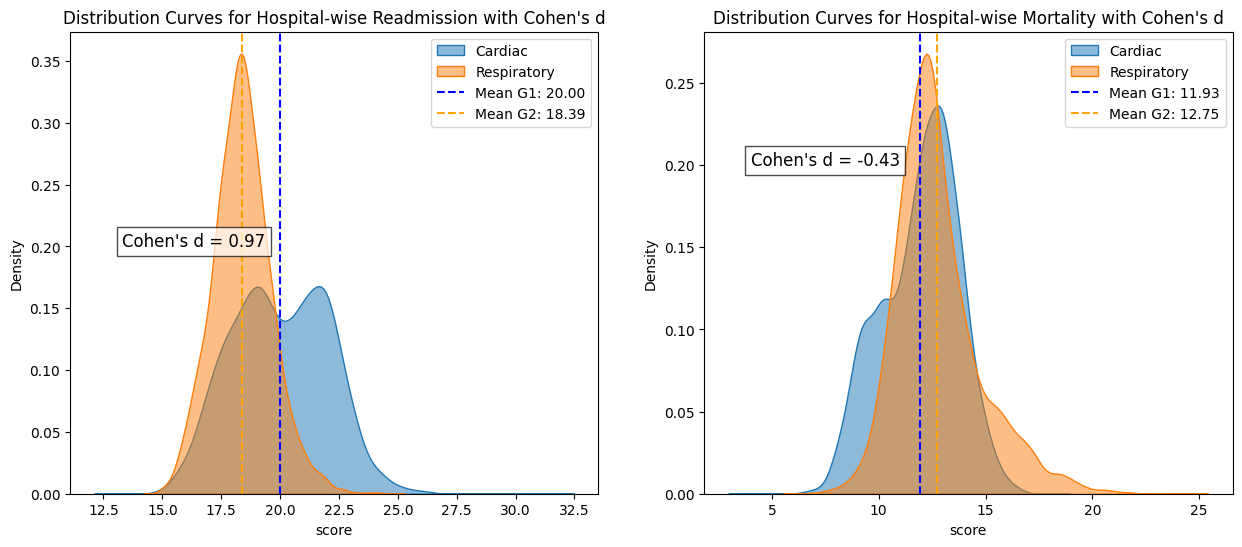

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
sns.kdeplot(hosp_cardiac_read, fill=True, label="Cardiac", alpha=0.5, ax=axes[0])
sns.kdeplot(hosp_resp_read, fill=True, label="Respiratory", alpha=0.5, ax=axes[0])
axes[0].set_title("Distribution Curves for Hospital-wise Readmission with Cohen's d")
#Mortality
sns.kdeplot(hosp_cardiac_mort, fill=True, label="Cardiac", alpha=0.5, ax=axes[1])
sns.kdeplot(hosp_resp_mort, fill=True, label="Respiratory", alpha=0.5, ax=axes[1])
axes[1].set_title("Distribution Curves for Hospital-wise Mortality with Cohen's d")


# Add mean lines
axes[0].axvline(np.mean(hosp_cardiac_read), color='blue', linestyle='--', label=f"Mean G1: {np.mean(hosp_cardiac_read):.2f}")
axes[0].axvline(np.mean(hosp_resp_read), color='orange', linestyle='--', label=f"Mean G2: {np.mean(hosp_resp_read):.2f}")

axes[1].axvline(np.mean(hosp_cardiac_mort), color='blue', linestyle='--', label=f"Mean G1: {np.mean(hosp_cardiac_mort):.2f}")
axes[1].axvline(np.mean(hosp_resp_mort), color='orange', linestyle='--', label=f"Mean G2: {np.mean(hosp_resp_mort):.2f}")

# Annotate Cohen's d
axes[0].text(x=min(min(hosp_cardiac_read), min(hosp_resp_read)), 
         y=0.2, 
         s=f"Cohen's d = {d1:.2f}", 
         fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.7))

axes[1].text(x=min(min(hosp_cardiac_mort), min(hosp_resp_mort)), 
         y=0.2, 
         s=f"Cohen's d = {d2:.2f}", 
         fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.7))

axes[0].legend()
axes[1].legend()
plt.show()


In [42]:
summary_data = []
def summary_stats(x, y, label, alpha=0.05):
    n1, n2 = len(x), len(y)
    m1, m2 = x.mean() , y.mean()
    std1, std2 = x.std(ddof=1), y.std(ddof=1)

    #Lavene test
    stat, lav_p = stats.levene(x,y)
    if lav_p < alpha:
        #Welch's test
        tstat, pval = stats.ttest_ind(x, y, equal_var=False)
    else:
        #t-test
        tstat, pval = stats.ttest_ind(x, y, equal_var=True)
    
    #pooled std
    pooled_std = np.sqrt(((n1-2) * std1**2 + (n2-2) * std2**2) / (n1+n2-2))

    #cohen's d
    d = (m1 - m2) / pooled_std

    #standard error of d
    se_d = np.sqrt((n1+n2) / (n1*n2) + (d**2) / (2 * (n1+n2 - 2)))
    
    #Critical z_value
    z_crit = stats.norm.ppf(1 - alpha/2)

    #Confidence Interval
    ci_lower = d - z_crit * se_d
    ci_upper = d + z_crit * se_d

    return summary_data.append({"Metric": label,
        "Cardiac Mean ± SD": f"{m1:.2f} ± {std1:.2f}",  
        "Respiratory Mean ± SD": f"{m2:.2f} ± {std2:.2f}",
        "t (df)": tstat,                         
        "p-value": pval,
        "Cohen’s d": f"{d:.3f}",
        "95% CI for d": f"[{ci_lower:.3f}, {ci_upper:.3f}]"})

    
summary_stats(hosp_cardiac_read, hosp_resp_read, "Readmission (%)")
summary_stats(hosp_cardiac_mort, hosp_resp_mort, "Mortality (%)")

summary_df = pd.DataFrame(summary_data)

summary_df


,Metric,Cardiac Mean ± SD,Respiratory Mean ± SD,t (df),p-value,Cohen’s d,95% CI for d
0,Readmission (%),20.00 ± 2.05,18.39 ± 1.24,40.549218,0.000000e+00,0.967,"[0.919, 1.015]"
1,Mortality (%),11.93 ± 1.79,12.75 ± 1.99,-18.624632,1.065853e-75,-0.434,"[-0.480, -0.387]"


# Conclusion & Recommendations
1. Summary of Findings

Readmission Rates:

Cardiac patients have significantly higher readmission rates than respiratory patients (Cohen’s d = 0.967, large effect).

This suggests that post-treatment care or discharge planning for cardiac cases may require closer attention.

Mortality Rates:

Cardiac patients have moderately lower mortality rates compared to respiratory patients (Cohen’s d = -0.434, moderate effect).

Indicates that while cardiac treatment outcomes (survival) are relatively good, preventing readmissions remains a challenge.

2. Implications for Hospital Management

High readmission rates for cardiac patients can increase costs (penalties from insurers/government programs) and signal gaps in post-discharge care.

Lower mortality but higher readmission suggests that patients survive initial treatment but may not receive adequate follow-up or self-care guidance.

3. Recommendations

For Cardiac Patients:

Implement structured discharge protocols with clear follow-up schedules.

Introduce telehealth monitoring within the first 30 days post-discharge.

Provide patient education programs on medication adherence, diet, and lifestyle.

For Respiratory Patients:

Investigate causes behind higher mortality — e.g., late diagnosis, severity on admission, or comorbidities.

Develop early detection and intervention programs for respiratory issues.

4. Limitations

Data scope may be limited to a specific region/hospital system — results may not generalize to all healthcare settings.

Readmission/mortality rates may be influenced by patient comorbidities not accounted for in this dataset.

Effect size interpretations are statistical — clinical significance should be verified with domain experts.

# Extra Insights

# State-level Readmission and Mortality Scores

In [43]:
# State-level ranking for Readmission
state_readmission_ranked = (
    available_data.query("measure_type == 'Readmission'")
    .groupby("state", as_index=False)["score"]
    .mean()
    .sort_values(by="score", ascending=True)  # Lower score is better
    .reset_index(drop=True)
    .rename(columns={'score':'readmission_rate(%)'})
)

state_readmission_ranked["rank_readmission"] = state_readmission_ranked["readmission_rate(%)"].rank(method="dense", ascending=True).astype(int)

# Calculate national average for Readmission
national_avg_read = pd.DataFrame({
    "state": ["national_average"],
    "readmission_rate(%)": [available_data.query("measure_type == 'Readmission'")["score"].mean()],
    "rank_readmission": 0
})

# Append national average
state_readmission_ranked = pd.concat([state_readmission_ranked, national_avg_read], ignore_index=True)

# State-level ranking for Mortality
state_mortality_ranked = (
    round(available_data.query("measure_type == 'Mortality'")
    .groupby("state", as_index=False)["score"]
    .mean(),2)
    .sort_values(by="score", ascending=True)  # Lower mortality is better
    .reset_index(drop=True)
    .rename(columns={'score':'mortality_rate(%)'})
)

state_mortality_ranked["rank_mortality"] = state_mortality_ranked["mortality_rate(%)"].rank(method="dense", ascending=True).astype(int)

# Calculate national average for Mortality
national_avg_mort = pd.DataFrame({
    "state": ["national_average"],
    "mortality_rate(%)": [available_data.query("measure_type == 'Mortality'")["score"].mean()],
    "rank_mortality": 0
})

# Append national average
state_mortality_ranked = pd.concat([state_mortality_ranked, national_avg_mort], ignore_index=True)

state_comparison = pd.merge(state_readmission_ranked, state_mortality_ranked, on="state").sort_values(by=["rank_readmission", "rank_mortality"], ascending=[True, True]).reset_index(drop=True)

state_comparison




,state,readmission_rate(%),rank_readmission,mortality_rate(%),rank_mortality
0,national_average,15.971395,0,12.474169,0
1,UT,14.528061,1,13.030000,33
2,ID,14.863580,2,13.110000,34
3,CO,14.954570,3,12.760000,24
4,VT,15.269412,4,13.320000,39
5,NH,15.294479,5,12.580000,17
6,MT,15.348352,6,13.300000,37
7,SD,15.351807,7,13.220000,35
8,WI,15.379438,8,12.760000,24
9,OR,15.380864,9,13.310000,38


In [44]:
# Exclude national average for plotting
plot_df = state_comparison[state_comparison["state"] != "national_average"].copy()

# Sort by readmission rank
plot_df = plot_df.sort_values("rank_readmission")

fig = go.Figure(data=[
    go.Bar(name='Readmission', x=plot_df["state"], y=plot_df["readmission_rate(%)"]),
    go.Bar(name='Mortality', x=plot_df["state"], y=plot_df["mortality_rate(%)"])
])
# Change the bar mode
fig.update_layout(title = "State-level Readmission vs Mortality Scores",
                  xaxis_title ='State',
                  yaxis_title = 'Average Score',
                  legend=dict(orientation='h',
                              yanchor = "bottom", y=1,
                              xanchor = "right", x=1),
                barmode='group', height = 700)
fig.show()

In [45]:
# State-level ranking for Readmission
state_readmission_ranked = (
    available_data.query("measure_type == 'Readmission'")
    .groupby(["state", "hospital_name"], as_index=False)["score"]
    .mean()
    .sort_values(by="score", ascending=True)  # Lower score is better
    .reset_index(drop=True)
    .rename(columns={'score':'readmission_rate(%)'})
)

state_readmission_ranked["rank_readmission"] = state_readmission_ranked.groupby("state")["readmission_rate(%)"].rank(method="dense", ascending=True).astype(int)

top3_hosp_read  = state_readmission_ranked[state_readmission_ranked["rank_readmission"].isin([1,2,3])]

# Calculate national average for Readmission
national_avg_read = pd.DataFrame({
    "state": ["national_average"],
    "readmission_rate(%)": [available_data.query("measure_type == 'Readmission'")["score"].mean()],
    "rank_readmission": 0
})

# Append national average
state_readmission_ranked = pd.concat([state_readmission_ranked, national_avg_read], ignore_index=True)

# State-level ranking for Mortality
state_mortality_ranked = (
    available_data.query("measure_type == 'Mortality'")
    .groupby(["state", "hospital_name"], as_index=False)["score"]
    .mean()
    .sort_values(by="score", ascending=True)  # Lower mortality is better
    .reset_index(drop=True)
    .rename(columns={'score':'mortality_rate(%)'})
)

state_mortality_ranked["rank_mortality"] = state_mortality_ranked.groupby("state")["mortality_rate(%)"].rank(method="dense", ascending=True).astype(int)

top3_hosp_mort  = state_mortality_ranked[state_mortality_ranked["rank_mortality"].isin([1,2,3])]

state_hosp_comparison = pd.merge(top3_hosp_read, top3_hosp_mort, on=["state", "hospital_name"]).sort_values(by=["state","rank_readmission", "rank_mortality"]).reset_index(drop=True)

state_hosp_comparison




,state,hospital_name,readmission_rate(%),rank_readmission,mortality_rate(%),rank_mortality
0,AK,PEACEHEALTH KETCHIKAN MEDICAL CENTER,14.200000,2,11.150000,3
1,CT,JOHN DEMPSEY HOSPITAL,14.962500,2,10.466667,3
2,DC,GEORGE WASHINGTON UNIV HOSPITAL,16.250000,2,10.716667,2
3,DC,MEDSTAR WASHINGTON HOSPITAL CENTER,16.275000,3,9.983333,1
4,DE,"CHRISTIANA CARE HEALTH SERVICES, INC.",15.075000,2,10.066667,1
5,GU,GUAM MEMORIAL HOSPITAL AUTHORITY,17.066667,1,15.900000,1
6,HI,THE QUEENS MEDICAL CENTER,14.087500,1,11.100000,2
7,HI,STRAUB CLINIC AND HOSPITAL,14.362500,2,10.916667,1
8,IA,MERCY HOSPITAL,13.300000,3,10.333333,2
9,MA,NORTH SHORE MEDICAL CENTER,14.625000,2,9.550000,3


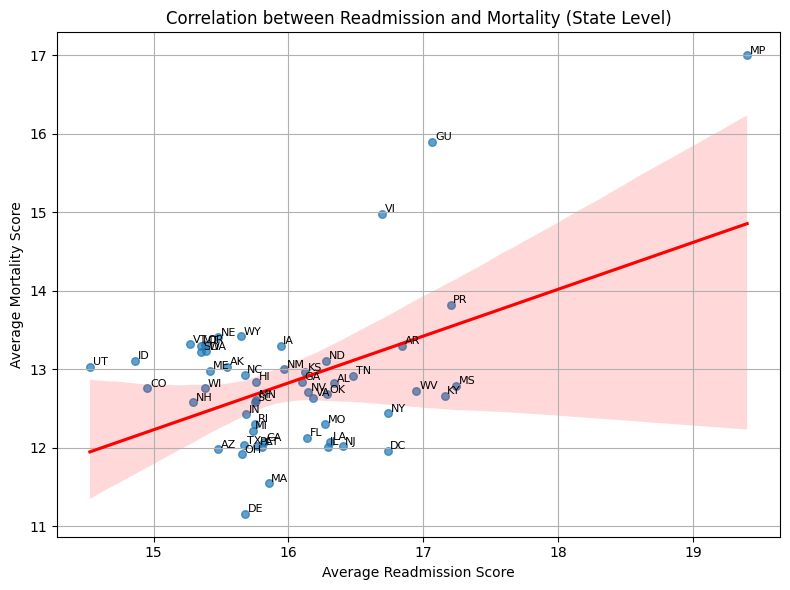

Correlation coefficient: 0.48


In [46]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(8, 6))
sns.regplot(
    data=plot_df,
    x="readmission_rate(%)",
    y="mortality_rate(%)",
    scatter_kws={"s": 30, "alpha": 0.7},
    line_kws={"color": "red"}
)

for i, row in plot_df.iterrows():
    plt.text(row["readmission_rate(%)"] + 0.02, row["mortality_rate(%)"] + 0.02, row["state"], fontsize=8)

plt.xlabel("Average Readmission Score")
plt.ylabel("Average Mortality Score")
plt.title("Correlation between Readmission and Mortality (State Level)")
plt.grid(True)
plt.tight_layout()
plt.show()

# Calculate correlation coefficient
corr_value = plot_df["readmission_rate(%)"].corr(plot_df["mortality_rate(%)"])
print(f"Correlation coefficient: {corr_value:.2f}")
